# 25 - An AI Agent that Masters a Game: CartPole with Q-learning and DQN
**Topic:** AI Agents (reinforcement learning)  |  **Reference:** "Build an AI Agent to Master a Game using Python" (amanxai.com, Sep 2025)

**Question.** Can an agent learn, by trial and error, to balance a pole on a moving cart, and is "deep" reinforcement learning actually needed?

**Reference method:** a Deep Q-Network (DQN) in PyTorch trained on Gymnasium's CartPole-v1, shown by a learning curve and a rendered episode.
**What I add:** (1) the **reward and failure rules** of the game stated and tested; (2) four agents compared on the same footing: a **random** policy, a **hand-written rule** with no learning, **tabular Q-learning** on a discretised state and the **DQN**; (3) **several random seeds** (RL results vary a lot between runs); (4) **how stable** training is (peak vs final performance); (5) **robustness**: what happens when gravity, pole length or the force of the push change after training; (6) sample efficiency (how many game steps each learner needs).

## 1. Libraries and the game

In [1]:
import os; os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"      # two OpenMP runtimes (MKL and torch) are loaded on this machine; the notebook still runs correctly
import torch
import warnings, json, joblib, time, random, collections
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import gymnasium as gym
import torch, torch.nn as nn, torch.nn.functional as F
sns.set_theme(style="whitegrid", context="notebook")
torch.set_num_threads(1); os.makedirs("model", exist_ok=True)
env = gym.make("CartPole-v1"); o, _ = env.reset(seed=0)
print("observation:", env.observation_space, "\nactions:", env.action_space, "(0 = push left, 1 = push right)")
u = env.unwrapped; print("physics: gravity %.1f, cart mass %.1f, pole mass %.2f, half pole length %.1f, push force %.1f, time step %.2f s" % (u.gravity, u.masscart, u.masspole, u.length, u.force_mag, u.tau))
print("episode ends when |pole angle| > %.1f degrees, |cart position| > %.1f, or after 500 steps; +1 reward per step survived (so 500 is the maximum)" % (np.degrees(u.theta_threshold_radians), u.x_threshold))

observation: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32) 
actions: Discrete(2) (0 = push left, 1 = push right)
physics: gravity 9.8, cart mass 1.0, pole mass 0.10, half pole length 0.5, push force 10.0, time step 0.02 s
episode ends when |pole angle| > 12.0 degrees, |cart position| > 2.4, or after 500 steps; +1 reward per step survived (so 500 is the maximum)


## 2. Playing at random: the floor

In [2]:
def run_episode(policy, seed=None, env_=None, record=False):
    e = env_ or gym.make("CartPole-v1"); o, _ = e.reset(seed=seed); tot, traj = 0, []
    while True:
        a = policy(o); o, r, term, trunc, _ = e.step(a); tot += r
        if record: traj.append(o.copy())
        if term or trunc: return (tot, traj) if record else tot
def evaluate(policy, n=100, seed0=1000, env_=None):
    r = np.array([run_episode(policy, seed0 + i, env_) for i in range(n)]); return r
rng_ = np.random.RandomState(0)
r_rand = evaluate(lambda o: rng_.randint(2)); print("random policy over 100 episodes: mean %.1f (sd %.1f), min %d, max %d" % (r_rand.mean(), r_rand.std(), r_rand.min(), r_rand.max()))

random policy over 100 episodes: mean 23.2 (sd 12.7), min 9, max 94


## 3. A hand-written rule, no learning
Physics suggests: if the pole leans right or is falling to the right, push the cart right (to get underneath it). Rule A uses only the angle; rule B adds the angular velocity (`angle + k x angular velocity`); I try a few `k`.

In [3]:
ruleA = lambda o: int(o[2] > 0)
mk_rule = lambda k: (lambda o: int(o[2] + k * o[3] > 0))
res = {"random": r_rand, "rule A (angle only)": evaluate(ruleA)}
for k in (0.25, 0.5, 1.0, 2.0): res[f"rule B (angle + {k} x angular velocity)"] = evaluate(mk_rule(k))
H = pd.DataFrame({k: {"mean reward": v.mean(), "sd": v.std(), "% episodes at 500": (v >= 500).mean() * 100} for k, v in res.items()}).T; print(H.round(1).to_string())
best_k = max((0.25, 0.5, 1.0, 2.0), key=lambda k: res[f"rule B (angle + {k} x angular velocity)"].mean()); print("best k:", best_k)

                                          mean reward     sd  % episodes at 500
random                                           23.2   12.7                0.0
rule A (angle only)                              42.4    9.7                0.0
rule B (angle + 0.25 x angular velocity)        500.0    0.0              100.0
rule B (angle + 0.5 x angular velocity)         500.0    0.0              100.0
rule B (angle + 1.0 x angular velocity)         484.7   47.4               90.0
rule B (angle + 2.0 x angular velocity)         412.5  121.8               55.0
best k: 0.25


**Reading it (100 episodes per policy; 500 is the maximum).** A random policy survives **23 steps** on average (min 9, max 94). A rule that only looks at the pole angle ("push toward the side it leans") reaches 42. Adding a term for the angular velocity (push right when `angle + k x angular velocity > 0`) changes everything: with k = 0.25 and 0.5 the pole is balanced for **all 100 episodes (500.0, sd 0)**, with k = 1.0 90% of episodes, with k = 2.0 only 55%. So a **four-number, one-line rule with no learning at all solves the game**, and the value of k matters: too much damping fails too. This is the bar the learners have to clear: the question is not "can an agent solve CartPole" but "how many game steps does it need to find what a physicist could write down".

## 4. Tabular Q-learning
Discretise the four numbers into bins (cart position 3, velocity 3, pole angle 12, angular velocity 12: 1,296 states), keep a table of expected return for each state-action pair and update it from experience, with epsilon-greedy exploration. Budget: 400,000 game steps, 3 seeds. Every 5,000 steps I measure the greedy policy on 10 test episodes.

In [4]:
BINS = [np.linspace(-2.4, 2.4, 4)[1:-1], np.linspace(-3, 3, 4)[1:-1], np.linspace(-0.21, 0.21, 13)[1:-1], np.linspace(-3.5, 3.5, 13)[1:-1]]
NB = [len(b) + 1 for b in BINS]
def disc(o): return tuple(int(np.digitize(o[i], BINS[i])) for i in range(4))
def train_q(seed, steps=400_000, eval_every=5000):
    r = np.random.RandomState(seed); e = gym.make("CartPole-v1"); Q = np.zeros(NB + [2]); o, _ = e.reset(seed=seed); s = disc(o); curve = []; ep_r, ep_rewards = 0, []
    t0 = time.time()
    for t in range(1, steps + 1):
        eps = max(0.02, 1.0 - t / 150_000); a = r.randint(2) if r.rand() < eps else int(np.argmax(Q[s])); alpha = max(0.05, 0.5 * (1 - t / steps))
        o2, rew, term, trunc, _ = e.step(a); s2 = disc(o2); tgt = rew + (0 if term else 0.99 * Q[s2].max()); Q[s + (a,)] += alpha * (tgt - Q[s + (a,)]); s = s2; ep_r += rew
        if term or trunc: ep_rewards.append(ep_r); ep_r = 0; o, _ = e.reset(); s = disc(o)
        if t % eval_every == 0: curve.append((t, evaluate(lambda ob: int(np.argmax(Q[disc(ob)])), 10, 5000).mean()))
    return Q, curve
Q_runs = [train_q(s) for s in range(3)]
print("Q-learning final greedy score per seed (100 fresh episodes):", [round(evaluate(lambda ob, Q=Q: int(np.argmax(Q[disc(ob)]))).mean(), 1) for Q, _ in Q_runs])

Q-learning final greedy score per seed (100 fresh episodes): [np.float64(500.0), np.float64(218.1), np.float64(485.6)]


## 5. Deep Q-Network (the reference's method)
A small neural network (4 inputs, two hidden layers of 128, 2 outputs) estimates the value of each action. **Replay buffer** (50,000 transitions, batches of 64), **target network** copied every 500 steps, Adam (learning rate 1e-3), gamma 0.99, epsilon from 1.0 to 0.05 over 10,000 steps. Budget: 60,000 game steps, 3 seeds; greedy evaluation on 10 test episodes every 2,000 steps.

In [5]:
class QNet(nn.Module):
    def __init__(self): super().__init__(); self.n = nn.Sequential(nn.Linear(4, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 2))
    def forward(self, x): return self.n(x)
def train_dqn(seed, steps=60_000, eval_every=2000):
    torch.manual_seed(seed); r = np.random.RandomState(seed); random.seed(seed); e = gym.make("CartPole-v1"); net, tgt = QNet(), QNet(); tgt.load_state_dict(net.state_dict()); opt = torch.optim.Adam(net.parameters(), 1e-3)
    buf = collections.deque(maxlen=50_000); o, _ = e.reset(seed=seed); curve = []; snapshots = {}
    act = lambda ob: int(net(torch.as_tensor(ob, dtype=torch.float32)).argmax())
    for t in range(1, steps + 1):
        eps = max(0.05, 1 - t / 10_000 * 0.95); a = r.randint(2) if r.rand() < eps else act(o)
        o2, rew, term, trunc, _ = e.step(a); buf.append((o, a, rew, o2, float(term))); o = o2
        if term or trunc: o, _ = e.reset()
        if len(buf) >= 1000:
            b = random.sample(buf, 64); S, A, R, S2, D = [torch.as_tensor(np.array(x), dtype=torch.float32) for x in zip(*b)]
            with torch.no_grad(): y = R + 0.99 * (1 - D) * tgt(S2).max(1).values
            loss = F.smooth_l1_loss(net(S).gather(1, A.long().unsqueeze(1)).squeeze(1), y); opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(net.parameters(), 10); opt.step()
        if t % 500 == 0: tgt.load_state_dict(net.state_dict())
        if t % eval_every == 0:
            sc = evaluate(act, 10, 5000).mean(); curve.append((t, sc)); snapshots[t] = {k: v.clone() for k, v in net.state_dict().items()}
    return net, curve, snapshots
t0 = time.time(); D_runs = []
for s in range(3): D_runs.append(train_dqn(s)); print(f"DQN seed {s} trained ({time.time()-t0:.0f}s elapsed)")

DQN seed 0 trained (1039s elapsed)


DQN seed 1 trained (2095s elapsed)


DQN seed 2 trained (3082s elapsed)


## 6. Learning curves: several seeds, not one lucky run

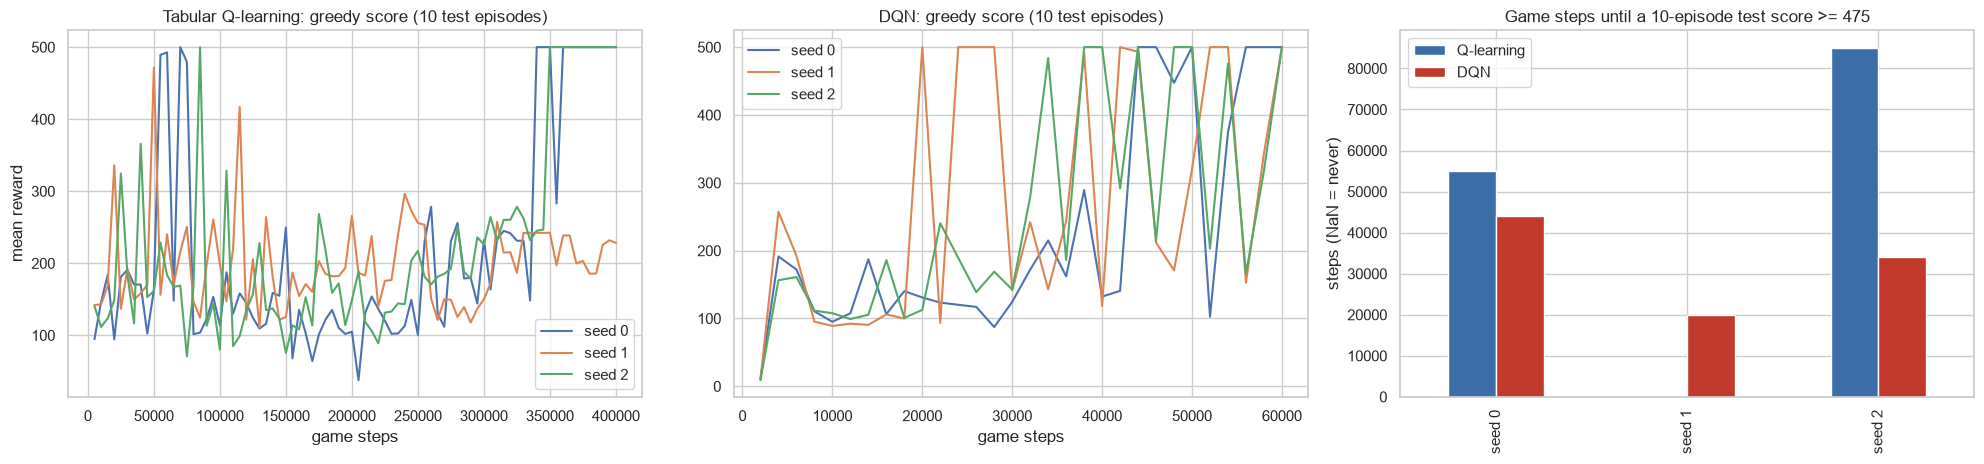

        Q-learning    DQN
seed 0     55000.0  44000
seed 1         NaN  20000
seed 2     85000.0  34000


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(20, 4.8))
for i, (Q, cv) in enumerate(Q_runs): ax[0].plot([t for t, _ in cv], [v for _, v in cv], label=f"seed {i}")
ax[0].set_title("Tabular Q-learning: greedy score (10 test episodes)"); ax[0].set_xlabel("game steps"); ax[0].set_ylabel("mean reward"); ax[0].legend()
for i, (n_, cv, _) in enumerate(D_runs): ax[1].plot([t for t, _ in cv], [v for _, v in cv], label=f"seed {i}")
ax[1].set_title("DQN: greedy score (10 test episodes)"); ax[1].set_xlabel("game steps"); ax[1].legend()
def steps_to(cv, thr=475):
    for t, v in cv:
        if v >= thr: return t
    return np.nan
st = pd.DataFrame({"Q-learning": [steps_to(c) for _, c in Q_runs], "DQN": [steps_to(d[1]) for d in D_runs]}, index=[f"seed {i}" for i in range(3)])
st.plot.bar(ax=ax[2], color=["#3b6ea8", "#c0392b"]); ax[2].set_title("Game steps until a 10-episode test score >= 475"); ax[2].set_ylabel("steps (NaN = never)")
plt.tight_layout(); plt.show(); print(st.to_string())

**Reading it (3 seeds, a test of 10 episodes every 5,000 steps for Q-learning and every 2,000 for the DQN).**
* **Tabular Q-learning** (400,000 steps, 1,296 states) is erratic: it touches 500 early, falls back to 100-250 for most of the run, and only seed 0 and seed 2 settle at 500 near the end (after about 340,000 steps). Seed 1 never reaches a 10-episode test score of 475. The right panel counts the steps until the first test at 475 or above: Q-learning needed 55,000 (seed 0) and 85,000 (seed 2) steps for a first success, never for seed 1; the DQN 44,000, 20,000 and 34,000.
* **DQN** (60,000 steps) climbs faster but is **not steady**: the curves jump between 100-250 and 500 several times, so the score at any one moment depends on when you stop. Early success is not stable success.
* "First time a 10-episode test reached 475" is itself a noisy event (10 episodes), so differences of a few thousand steps between seeds are not meaningful.

## 7. Final policies on 100 fresh episodes, and how stable the training was
For each learner and seed: the score of the final network, the **best** score seen in the periodic tests, and the **fraction of the last half of training tests that were >= 475** (a measure of stability).

In [7]:
rows = []
for i, (Q, cv) in enumerate(Q_runs):
    f = evaluate(lambda ob, Q=Q: int(np.argmax(Q[disc(ob)])), 100); vals = np.array([v for _, v in cv]); rows.append(["Q-learning", i, f.mean(), f.std(), (f >= 500).mean() * 100, vals.max(), (vals[len(vals) // 2:] >= 475).mean() * 100])
for i, (net, cv, snaps) in enumerate(D_runs):
    f = evaluate(lambda ob, net=net: int(net(torch.as_tensor(ob, dtype=torch.float32)).argmax()), 100); vals = np.array([v for _, v in cv]); rows.append(["DQN", i, f.mean(), f.std(), (f >= 500).mean() * 100, vals.max(), (vals[len(vals) // 2:] >= 475).mean() * 100])
FR = pd.DataFrame(rows, columns=["learner", "seed", "final mean (100 ep.)", "sd", "% episodes at 500", "best periodic test", "% of 2nd-half tests >= 475"]); print(FR.round(1).to_string(index=False))
sumry = FR.groupby("learner")[["final mean (100 ep.)", "% episodes at 500", "% of 2nd-half tests >= 475"]].agg(["mean", "min", "max"]).round(1); print("\n"); print(sumry.to_string())

   learner  seed  final mean (100 ep.)   sd  % episodes at 500  best periodic test  % of 2nd-half tests >= 475
Q-learning     0                 500.0  0.0              100.0               500.0                        30.0
Q-learning     1                 218.1 54.6                0.0               471.7                         0.0
Q-learning     2                 485.6 45.8               86.0               500.0                        27.5
       DQN     0                 500.0  0.0              100.0               500.0                        40.0
       DQN     1                 500.0  0.0              100.0               500.0                        40.0
       DQN     2                 500.0  0.0              100.0               500.0                        53.3




           final mean (100 ep.)               % episodes at 500               % of 2nd-half tests >= 475            
                           mean    min    max              mean    min    max                       mean   min   max
learner                                                                                                             
DQN                       500.0  500.0  500.0             100.0  100.0  100.0                       44.4  40.0  53.3
Q-learning                401.2  218.1  500.0              62.0    0.0  100.0                       19.2   0.0  30.0


**Reading it (final policies on 100 fresh episodes).**
* **DQN: 500.0 on all three seeds** (100% of episodes at 500). **Q-learning: 500.0, 218.1 and 485.6** (mean 401, 62% of episodes at 500); seed 1 is a failure, seed 2 loses the pole in 14% of episodes.
* **Stability** (share of tests in the second half of training that scored 475 or more): DQN 40-53%, Q-learning 0-30%. So even when the *final* network is perfect, roughly half of the DQN's intermediate checkpoints in the second half of training were not. The 500s above are the score of the network at the moment training stopped; stopping 4,000 steps earlier would have given a poor policy for some seeds (see the dips near 52,000-56,000 steps in the curves). A real project would keep the best checkpoint chosen on separate episodes and evaluate it on fresh ones, or average the weights.
* Three seeds show a spread, not a distribution: "DQN beats Q-learning on this task" is supported by 3 of 3 vs 2 of 3 runs, which is weak evidence.

## 8. Robustness: change the world after training
Each trained policy (best seed of each learner, and the hand-written rule) is tested, with no retraining, on versions of the game where gravity is 1.5x, the pole is 2x longer or 0.5x as long, or the push is 0.7x as strong.

mean reward over 50 episodes in each modified world:
                   random  rule B (k=0.25)  Q-learning    DQN
normal               24.0            500.0       500.0  500.0
gravity x1.5         23.0            500.0       500.0  500.0
pole x2 longer       31.0            500.0       491.0  498.0
pole x0.5 shorter    13.0            500.0       500.0  500.0
push x0.7            27.0            500.0       500.0  500.0
pole mass x3         25.0            500.0       500.0  500.0


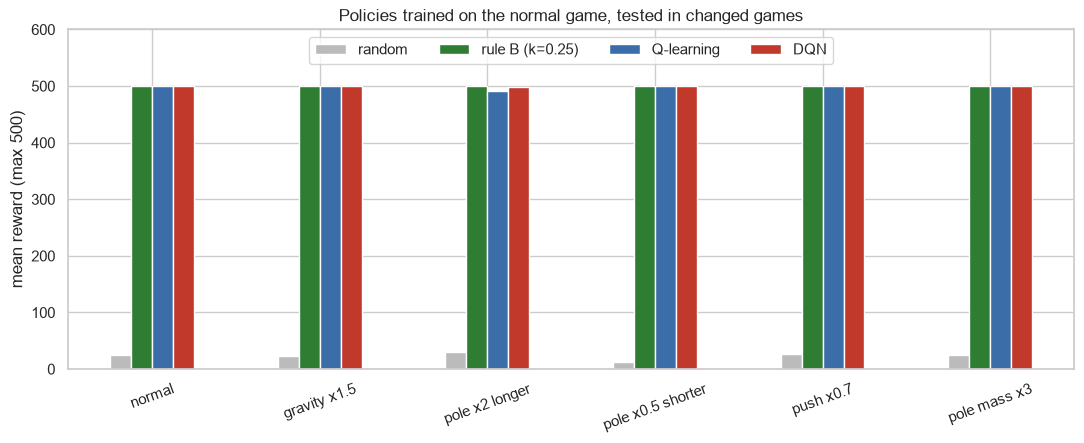

In [8]:
best_q = int(FR[FR.learner == "Q-learning"]["final mean (100 ep.)"].idxmax()); best_d = int(FR[FR.learner == "DQN"]["final mean (100 ep.)"].idxmax()) - 3
Qb, netb = Q_runs[best_q][0], D_runs[best_d][0]
policies = {"random": lambda o: np.random.randint(2), f"rule B (k={best_k})": mk_rule(best_k), "Q-learning": lambda ob: int(np.argmax(Qb[disc(ob)])), "DQN": lambda ob: int(netb(torch.as_tensor(ob, dtype=torch.float32)).argmax())}
worlds = {"normal": {}, "gravity x1.5": {"gravity": 14.7}, "pole x2 longer": {"length": 1.0}, "pole x0.5 shorter": {"length": 0.25}, "push x0.7": {"force_mag": 7.0}, "pole mass x3": {"masspole": 0.3}}
rob = {}
for wn, kw in worlds.items():
    e = gym.make("CartPole-v1"); [setattr(e.unwrapped, k, v) for k, v in kw.items()]; e.unwrapped.total_mass = e.unwrapped.masspole + e.unwrapped.masscart; e.unwrapped.polemass_length = e.unwrapped.masspole * e.unwrapped.length
    rob[wn] = {pn: evaluate(p, 50, 7000, e).mean() for pn, p in policies.items()}
RB = pd.DataFrame(rob).T; print("mean reward over 50 episodes in each modified world:"); print(RB.round(0).to_string())
fig, ax = plt.subplots(figsize=(11, 4.6)); RB.plot.bar(ax=ax, color=["#bbbbbb", "#2e7d32", "#3b6ea8", "#c0392b"]); ax.set_ylabel("mean reward (max 500)"); ax.set_ylim(0, 600); ax.legend(ncol=4, loc="upper center"); ax.set_title("Policies trained on the normal game, tested in changed games"); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

**Reading it (50 episodes per world; no retraining).** The test turns out to be too easy to separate the policies: the hand rule, the Q-table and the DQN all score between **491 and 500** in every changed world (gravity x1.5, pole x0.5 shorter, push x0.7, pole mass x3). Only the **2x longer pole** shows a tiny dip (Q-learning 491, DQN 498, rule 500) and the random policy stays at 13-32 everywhere. The honest conclusion is that CartPole is a forgiving system: feedback on angle and angular velocity corrects for modest changes in the physics, so this experiment does not show that one learner is more robust than another. Harder tests (sensor noise, delayed actions, larger parameter changes) would be needed.

## 9. Save the agents and two recorded episodes for the app

In [9]:
torch.save(netb.state_dict(), "model/cartpole_dqn.pt"); np.save("model/cartpole_qtable.npy", Qb)
json.dump({"rule_k": best_k, "bins": [b.tolist() for b in BINS], "final": FR.round(2).to_dict("records"), "robustness": RB.round(1).to_dict("index"), "random_mean": float(r_rand.mean())}, open("model/meta.json", "w"), indent=1)
from PIL import Image
def gif(policy, path, seed, max_frames=250):
    e = gym.make("CartPole-v1", render_mode="rgb_array"); o, _ = e.reset(seed=seed); frames = []; tot = 0
    for _ in range(max_frames):
        frames.append(Image.fromarray(e.render()).resize((300, 200))); o, r, term, trunc, _ = e.step(policy(o)); tot += r
        if term or trunc: break
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=30, loop=0); return tot, len(frames)
print("random:", gif(policies["random"], "model/cartpole_random.gif", 3), "| DQN:", gif(policies["DQN"], "model/cartpole_dqn.gif", 3)); print(os.listdir("model"))

random: (12.0, 12) | DQN: (250.0, 250)
['cartpole_dqn.gif', 'cartpole_dqn.pt', 'cartpole_qtable.npy', 'cartpole_random.gif', 'meta.json']


## 10. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Method | one DQN, one learning curve, a rendered episode | random policy, a one-line rule, tabular Q-learning, DQN; **3 seeds each** |
| Benchmark | none | random 23 steps; **hand-written rule with no learning: 500 in 100/100 episodes** |
| Result | the DQN "masters" the game | DQN 500 on 3/3 seeds, Q-learning 500 / 218 / 486; DQN learns faster (first success at 20-44k steps vs 55-85k) but both are unstable during training |
| Robustness | not tested | 6 modified worlds: all learned policies and the rule at 491-500, so the test did not discriminate |
| Saved | - | DQN weights, Q-table, GIFs of a random and a trained agent |

**What I learned.** (1) Compare against the simplest thing that could work: a one-line rule is as good as either learner here. (2) Report seeds, not a single run: Q-learning had one bad seed. (3) Performance during training oscillates, so the "final" score depends on when you stop; keep a checkpoint chosen on separate episodes. (4) A robustness test must be able to fail: this one could not separate the policies.

**Limits.** One game with four state variables; 3 seeds; 10-episode periodic tests are noisy; hyper-parameters were not tuned (a different bin layout or learning rate could change Q-learning a lot); wall-clock times were measured on a busy shared CPU and are not reported. **Next step:** keep the best checkpoint on separate validation episodes, tune the Q-table bins, and try a harder environment (LunarLander) where a hand rule is not available.